# IEEE-CIS Fraud Detection — Data Audit & Exploratory Data Analysis

**Project:** AQ-FL (Adversarial Post-Quantum Federated Learning) — fraud detection across 10 simulated financial-institution clients using the Flower (`flwr`) framework with an MLP classifier.

**Purpose of this notebook:** audit and explore the IEEE-CIS dataset *before* any model code is written. Findings feed the Data Audit & EDA section of Chapter 3 of the dissertation.

**Dataset:** Kaggle competition *ieee-fraud-detection* (Vesta Corporation, 2019) — real, anonymised e-commerce transaction data.

| File | Approx. size | Content |
|---|---|---|
| `train_transaction.csv` | ~590K rows × 394 cols | Transactions, label `isFraud` |
| `train_identity.csv` | ~144K rows × 41 cols | Device/identity info for a subset of transactions |

The two tables join on `TransactionID` (left join — not every transaction has an identity record).

**Scope:** audit and EDA only. No imputation, feature engineering, scaling, or model code in this notebook.

> **Execution note:** loading the raw CSVs requires roughly 3–4 GB of RAM. Run cells top to bottom.

**Contents**
1. Dataset Overview
2. Structural Audit (Phase 1)
3. Class Balance Analysis
4. Univariate EDA (TransactionAmt, TransactionDT, ProductCD, cards, C1-C14, D1-D15)
5. Fraud-Stratified Analysis
6. Outlier Analysis
7. FL Partitioning Analysis (Dirichlet, non-IID characterisation)
8. Data Card (Gebru et al. 2021)

### Environment setup

Install the required packages (no-op if already installed). Audit/EDA only: pandas, matplotlib, seaborn.

In [1]:
%pip install -q pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("deep")
pd.set_option("display.max_columns", 120)

RANDOM_STATE = 42

In [3]:
import sys
print(f"Python {sys.version.split()[0]}")
print(f"numpy {np.__version__} | pandas {pd.__version__}")
import matplotlib
print(f"matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")

Python 3.13.9
numpy 2.3.5 | pandas 2.3.3
matplotlib 3.10.6 | seaborn 0.13.2


In [4]:
DATA_DIR = Path("../Data/IEEE-CIS_Fraud_Detection")
TXN_PATH = DATA_DIR / "train_transaction.csv"
ID_PATH = DATA_DIR / "train_identity.csv"
assert TXN_PATH.exists() and ID_PATH.exists(), "Data files not found - check DATA_DIR"

## 1. Dataset Overview

This section loads both tables, documents their shape and column structure, and quantifies the coverage of the transaction–identity join.

In [5]:
txn = pd.read_csv(TXN_PATH)
idn = pd.read_csv(ID_PATH)
print(f"train_transaction: {txn.shape[0]:,} rows x {txn.shape[1]} columns")
print(f"train_identity:    {idn.shape[0]:,} rows x {idn.shape[1]} columns")

train_transaction: 590,540 rows x 394 columns
train_identity:    144,233 rows x 41 columns


In [6]:
print("train_transaction dtype counts:")
print(txn.dtypes.value_counts().to_string(), "\n")
print("train_identity dtype counts:")
print(idn.dtypes.value_counts().to_string())

train_transaction dtype counts:
float64    376
object      14
int64        4 

train_identity dtype counts:
float64    23
object     17
int64       1


In [7]:
def col_group(c):
    c = str(c)
    if re.match(r"^card\d", c):
        return "card*"
    if re.match(r"^addr\d", c):
        return "addr*"
    if re.match(r"^dist\d", c):
        return "dist*"
    if re.match(r"^C\d+$", c):
        return "C*"
    if re.match(r"^D\d+$", c):
        return "D*"
    if re.match(r"^M\d+$", c):
        return "M*"
    if re.match(r"^V\d+$", c):
        return "V*"
    if c.startswith(("id_", "id-")):
        return "id_*"
    return "other"

all_cols = list(txn.columns) + [c for c in idn.columns if c != "TransactionID"]
groups = {}
for c in all_cols:
    groups.setdefault(col_group(c), []).append(c)

for key in ["card*", "addr*", "dist*", "C*", "D*", "M*", "V*", "id_*", "other"]:
    cols = groups.get(key, [])
    print(f"{key:>6}: {len(cols):>3} columns | e.g. {cols[:5]}")

 card*:   6 columns | e.g. ['card1', 'card2', 'card3', 'card4', 'card5']
 addr*:   2 columns | e.g. ['addr1', 'addr2']
 dist*:   2 columns | e.g. ['dist1', 'dist2']
    C*:  14 columns | e.g. ['C1', 'C2', 'C3', 'C4', 'C5']
    D*:  15 columns | e.g. ['D1', 'D2', 'D3', 'D4', 'D5']
    M*:   9 columns | e.g. ['M1', 'M2', 'M3', 'M4', 'M5']
    V*: 339 columns | e.g. ['V1', 'V2', 'V3', 'V4', 'V5']
  id_*:  38 columns | e.g. ['id_01', 'id_02', 'id_03', 'id_04', 'id_05']
 other:   9 columns | e.g. ['TransactionID', 'isFraud', 'TransactionDT', 'TransactionAmt', 'ProductCD']


The column families follow Vesta's documented schema: `card*` (card attributes), `addr*` (billing region), `dist*` (distances), `C1–C14` (anonymised counts), `D1–D15` (time deltas in days), `M1–M9` (match flags), `V1–V339` (Vesta-engineered, anonymised features), and `id_*` plus `DeviceType`/`DeviceInfo` from the identity table.

In [8]:
txn.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10,D11,D12,D13,D14,D15,M1,M2,M3,M4,M5,M6,M7,M8,M9,V1,V2,V3,V4,V5,...,V280,V281,V282,V283,V284,V285,V286,V287,V288,V289,V290,V291,V292,V293,V294,V295,V296,V297,V298,V299,V300,V301,V302,V303,V304,V305,V306,V307,V308,V309,V310,V311,V312,V313,V314,V315,V316,V317,V318,V319,V320,V321,V322,V323,V324,V325,V326,V327,V328,V329,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,credit,315.0,87.0,19.0,NaN,NaN,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,2.0,0.0,1.0,1.0,14.0,NaN,13.0,NaN,NaN,NaN,NaN,NaN,NaN,13.0,13.0,NaN,NaN,NaN,0.0,T,T,T,M2,F,T,NaN,NaN,NaN,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,117.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,117.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,credit,325.0,87.0,NaN,NaN,gmail.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,M0,T,T,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,debit,330.0,87.0,287.0,NaN,outlook.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,315.0,NaN,NaN,NaN,315.0,T,T,T,M0,F,F,F,F,F,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,debit,476.0,87.0,NaN,NaN,yahoo.com,NaN,2.0,5.0,0.0,0.0,0.0,4.0,0.0,0.0,1.0,0.0,1.0,0.0,25.0,1.0,112.0,112.0,0.0,94.0,0.0,NaN,NaN,NaN,NaN,84.0,NaN,NaN,NaN,NaN,111.0,NaN,NaN,NaN,M0,T,F,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,28.0,0.0,0.0,0.0,0.0,10.0,0.0,4.0,0.0,0.0,1.0,1.0,1.0,1.0,38.0,24.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,50.0,1758.0,925.0,0.0,354.0,0.0,135.0,0.0,0.0,0.0,50.0,1404.0,790.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,credit,420.0,87.0,NaN,NaN,gmail.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [9]:
txn.tail()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10,D11,D12,D13,D14,D15,M1,M2,M3,M4,M5,M6,M7,M8,M9,V1,V2,V3,V4,V5,...,V280,V281,V282,V283,V284,V285,V286,V287,V288,V289,V290,V291,V292,V293,V294,V295,V296,V297,V298,V299,V300,V301,V302,V303,V304,V305,V306,V307,V308,V309,V310,V311,V312,V313,V314,V315,V316,V317,V318,V319,V320,V321,V322,V323,V324,V325,V326,V327,V328,V329,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
590535,3577535,0,15811047,49.00,W,6550,NaN,150.0,visa,226.0,debit,272.0,87.0,48.0,NaN,NaN,NaN,2.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0,0.0,1.0,0.0,3.0,2.0,29.0,29.0,30.0,NaN,NaN,NaN,NaN,NaN,NaN,56.0,56.0,NaN,NaN,NaN,56.0,T,T,T,M0,T,F,F,F,T,1.0,1.0,1.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.000000,47.950001,0.000000,0.0,47.950001,0.0,0.0,47.950001,47.950001,47.950001,0.0,0.0,0.0,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
590536,3577536,0,15811049,39.50,W,10444,225.0,150.0,mastercard,224.0,debit,204.0,87.0,NaN,NaN,gmail.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,0.0,T,F,F,M0,F,T,F,F,F,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
590537,3577537,0,15811079,30.95,W,12037,595.0,150.0,mastercard,224.0,debit,231.0,87.0,NaN,NaN,gmail.com,NaN,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,0.0,T,F,F,NaN,NaN,T,NaN,NaN,NaN,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
590538,3577538,0,15811088,117.00,W,7826,481.0,150.0,mastercard,224.0,debit,387.0,87.0,3.0,NaN,aol.com,NaN,1.0,1.0,0.0,0.0,0.0,3.0,0.0,0.0,2.0,0.0,1.0,1.0,5.0,1.0,22.0,22.0,0.0,22.0,0.0,NaN,NaN,NaN,NaN,22.0,22.0,NaN,NaN,NaN,22.0,T,T,T,M0,F,T,NaN,NaN,NaN,1.0,1.0,1.0,2.0,2.0,...,1.0,0.0,2.0,7.0,1.0,5.0,0.0,1.0,1.0,1.0,1.0,2.0,1.0,0.0,11.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,117.000000,2903.500000,117.000000,117.0,669.500000,0.0,117.0,317.500000,669.500000,317.500000,0.0,2234.0,0.0,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
590539,3577539,0,15811131,279.95,W,15066,170.0,150.0,mastercard,102.0,credit,299.0,87.0,NaN,NaN,gmail.com,NaN,2.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,2.0,0.0,1.0,0.0,1.0,1.0,0.0,NaN,0.0,1.0,0.0,NaN,NaN,NaN,NaN,1.0,0.0,NaN,NaN,NaN,1.0,T,F,F,NaN,NaN,T,F,F,F,1.0,1.0,1.0,1.0,1.0,...,1.0,0.0,2.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,279.950012,279.950012,279.950012,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,279.950012,279.950012,279.950012,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
df = txn.merge(idn, on="TransactionID", how="left")
has_identity = txn["TransactionID"].isin(idn["TransactionID"])
n_matched = int(has_identity.sum())
print(f"Joined shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Transactions with an identity record: {n_matched:,} of {len(txn):,} ({n_matched / len(txn):.2%})")

Joined shape: 590,540 rows x 434 columns
Transactions with an identity record: 144,233 of 590,540 (24.42%)


Only about a quarter of transactions carry an identity record; the left join preserves all transactions and leaves identity fields missing for the remainder. This coverage figure is a *structural* property of the data collection, not a quality defect.

## 2. Structural Audit (Phase 1)

Duplicates, missingness, and dtype integrity.

In [11]:
print("Full-row duplicates (transaction table):", int(txn.duplicated().sum()))
print("Duplicate TransactionID (transaction): ", int(txn["TransactionID"].duplicated().sum()))
print("Duplicate TransactionID (identity):    ", int(idn["TransactionID"].duplicated().sum()))

Full-row duplicates (transaction table): 0
Duplicate TransactionID (transaction):  0
Duplicate TransactionID (identity):     0


In [12]:
null_rate = df.isna().mean().sort_values(ascending=False)
null_rate.head(20).to_frame("null_rate").style.format({"null_rate": "{:.2%}"})

,null_rate
id_24,99.20%
id_25,99.13%
id_07,99.13%
id_08,99.13%
id_21,99.13%
id_26,99.13%
id_27,99.12%
id_23,99.12%
id_22,99.12%
dist2,93.63%


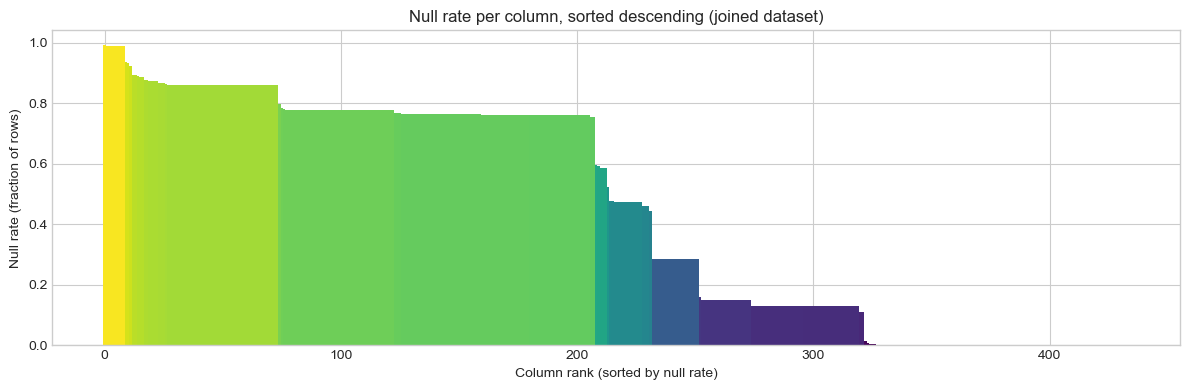

In [13]:
fig, ax = plt.subplots(figsize=(12, 4))
vals = null_rate.values
ax.bar(range(len(vals)), vals, width=1.0, color=plt.cm.viridis(vals))
ax.set_title("Null rate per column, sorted descending (joined dataset)")
ax.set_xlabel("Column rank (sorted by null rate)")
ax.set_ylabel("Null rate (fraction of rows)")
plt.tight_layout()
plt.show()

The profile shows long plateaus of near-identical null rates — whole blocks of `V*` and `id_*` columns are missing together, indicating *structured* (block-wise) missingness rather than random data loss.

> **⚠️ Note on V1–V339 missingness.** The `V` columns are Vesta-engineered features whose null rates reach ~86% in this training split (figures of up to ~90% are commonly cited) **by design**: each V-block is only populated for the transaction sub-population it was engineered for (part of Vesta's anonymisation strategy). This is **structured missingness, not a data-quality failure**. These columns should **not** be dropped or aggressively imputed on the basis of null rate alone; the missingness pattern itself is informative and will be handled explicitly at the preprocessing stage.

In [14]:
v_cols = [c for c in df.columns if re.match(r"^V\d+$", c)]
v_null = df[v_cols].isna().mean()
print(f"V columns: {len(v_cols)}")
print(f"Null rate across V columns - min: {v_null.min():.1%}, median: {v_null.median():.1%}, max: {v_null.max():.1%}")

V columns: 339
Null rate across V columns - min: 0.0%, median: 47.3%, max: 86.1%


In [15]:
id_cols = [c for c in df.columns if c.startswith(("id_", "id-"))] + ["DeviceType", "DeviceInfo"]
id_null = df[id_cols].isna().mean().sort_values(ascending=False)
print(f"Identity columns after left join: {len(id_cols)}")
print(f"Null rate - min: {id_null.min():.1%}, median: {id_null.median():.1%}, max: {id_null.max():.1%}")
print(f"\n(Baseline: {1 - n_matched / len(txn):.1%} of rows have no identity record at all.)")

Identity columns after left join: 40
Null rate - min: 75.6%, median: 79.2%, max: 99.2%

(Baseline: 75.6% of rows have no identity record at all.)


Identity-field missingness after the join is dominated by the ~76% of transactions with no identity record; column-level nulls above that baseline reflect optional fields within matched records.

In [16]:
object_cols = df.select_dtypes(include="object").columns
suspicious = []
for c in object_cols:
    sample = df[c].dropna().head(1000)
    if len(sample) > 0 and pd.to_numeric(sample, errors="coerce").notna().mean() > 0.95:
        suspicious.append(c)
print(f"Object-dtype columns: {len(object_cols)}")
print("Object columns that look numeric:", suspicious if suspicious else "none")

Object-dtype columns: 31
Object columns that look numeric: none


No full-row duplicates and no duplicated `TransactionID` in either table, so the join key is a clean primary key. Missingness is block-structured rather than random, and no object-typed column masks numeric data — dtypes are consistent with the documented schema.

*Working note: the first instinct was to drop every column above a null-rate threshold. Reading Vesta's schema notes made clear that the V-block pattern is itself a signal, so the threshold rule was abandoned.*

## 3. Class Balance Analysis

In [17]:
counts = txn["isFraud"].value_counts().sort_index()
pct = txn["isFraud"].value_counts(normalize=True).sort_index() * 100
balance = pd.DataFrame({"count": counts.values, "percent": pct.round(3).values},
                       index=["Legitimate (0)", "Fraud (1)"])
balance

,count,percent
Legitimate (0),569877,96.501
Fraud (1),20663,3.499


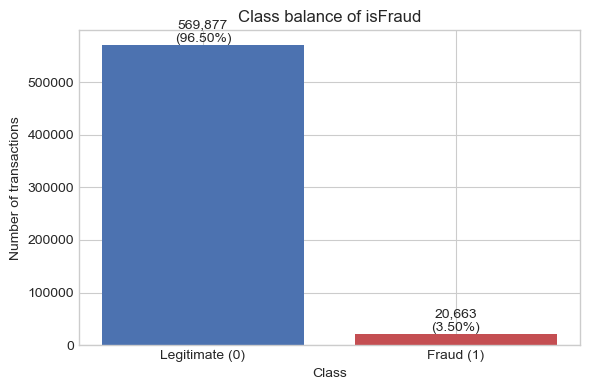

In [18]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(balance.index, balance["count"], color=["#4C72B0", "#C44E52"])
for i, (n, p) in enumerate(zip(balance["count"], balance["percent"])):
    ax.text(i, n, f"{n:,}\n({p:.2f}%)", ha="center", va="bottom")
ax.set_title("Class balance of isFraud")
ax.set_xlabel("Class")
ax.set_ylabel("Number of transactions")
plt.tight_layout()
plt.show()

Fraudulent transactions account for roughly 3.5% of the dataset — a severe class imbalance.

**Methodological consequence:** with ~3.5% positives, raw accuracy is uninformative (a trivial all-negative classifier scores ~96.5%). The FL experiments will therefore use **AUC-ROC as the primary evaluation metric** and a **class-weighted loss in the MLP** to counteract the imbalance during training.

**Key Findings — Section 3**
- The label is heavily imbalanced (~3.5% fraud), consistent with real-world e-commerce fraud prevalence.
- AUC-ROC is adopted as the primary metric; accuracy is reported only as a secondary figure.
- Class-weighted loss is justified for MLP training; resampling decisions are deferred to the preprocessing stage.

## 4. Univariate EDA

### 4.1 TransactionAmt

In [19]:
amt = txn["TransactionAmt"]
amt.describe().to_frame("TransactionAmt")

,TransactionAmt
count,590540.000000
mean,135.027176
std,239.162522
min,0.251000
25%,43.321000
50%,68.769000
75%,125.000000
max,31937.391000


In [20]:
pearson_skew = 3 * (amt.mean() - amt.median()) / amt.std()
print(f"Mean: {amt.mean():,.2f} | Median: {amt.median():,.2f} | SD: {amt.std():,.2f}")
print(f"Pearson's skewness coefficient (3*(mean-median)/std): {pearson_skew:.3f}")
print(f"Moment skewness (pandas .skew()): {amt.skew():.2f}")

Mean: 135.03 | Median: 68.77 | SD: 239.16
Pearson's skewness coefficient (3*(mean-median)/std): 0.831
Moment skewness (pandas .skew()): 14.37


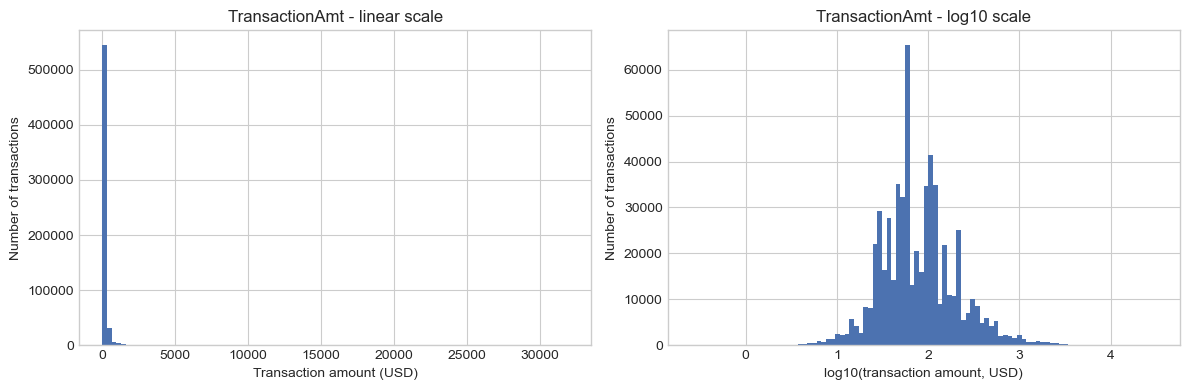

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(amt, bins=100, color="#4C72B0")
axes[0].set_title("TransactionAmt - linear scale")
axes[0].set_xlabel("Transaction amount (USD)")
axes[0].set_ylabel("Number of transactions")
axes[1].hist(np.log10(amt[amt > 0]), bins=100, color="#4C72B0")
axes[1].set_title("TransactionAmt - log10 scale")
axes[1].set_xlabel("log10(transaction amount, USD)")
axes[1].set_ylabel("Number of transactions")
plt.tight_layout()
plt.show()

On the linear scale the distribution collapses into the first bins, while the log scale reveals a roughly log-normal shape centred near USD 50–100 — classic heavy right skew in monetary amounts. The two skewness coefficients diverge sharply (Pearson's ≈ 0.83 vs moment skewness ≈ 14.4) because the median-based Pearson measure is insensitive to the extreme upper tail; the moment coefficient better reflects the severity of the skew.

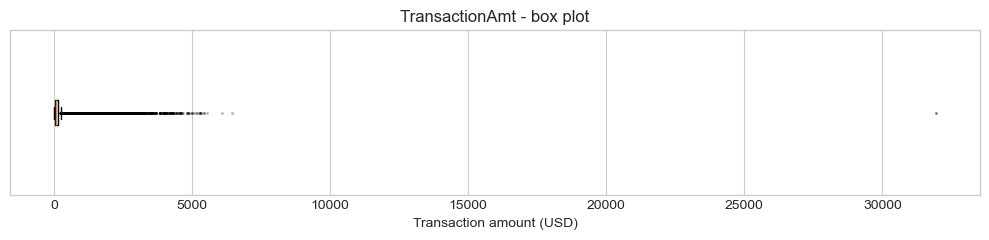

In [22]:
fig, ax = plt.subplots(figsize=(10, 2.5))
ax.boxplot(amt, vert=False, showfliers=True, flierprops={"markersize": 1, "alpha": 0.3})
ax.set_title("TransactionAmt - box plot")
ax.set_xlabel("Transaction amount (USD)")
ax.set_yticks([])
plt.tight_layout()
plt.show()

The box plot confirms a compact interquartile range (tens of USD) against a long tail of high-value transactions reaching tens of thousands of USD.

### 4.2 TransactionDT (time)

In [23]:
days = txn["TransactionDT"] / 86400
print(f"TransactionDT range: {txn['TransactionDT'].min():,} s to {txn['TransactionDT'].max():,} s")
print(f"= day {days.min():.2f} to day {days.max():.2f} from reference point "
      f"(~{(days.max() - days.min()) / 30.44:.1f} months of activity)")

TransactionDT range: 86,400 s to 15,811,131 s
= day 1.00 to day 183.00 from reference point (~6.0 months of activity)


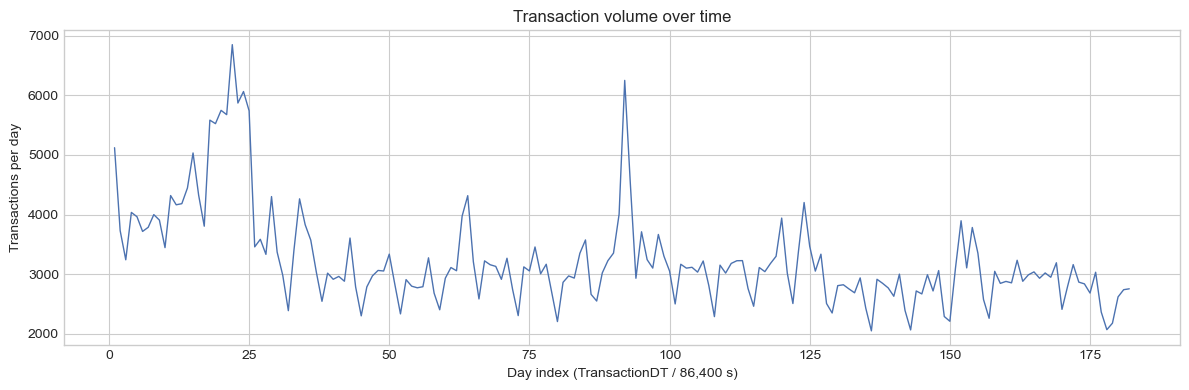

In [24]:
daily_volume = txn.groupby(days.astype(int)).size()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily_volume.index, daily_volume.values, color="#4C72B0", lw=1)
ax.set_title("Transaction volume over time")
ax.set_xlabel("Day index (TransactionDT / 86,400 s)")
ax.set_ylabel("Transactions per day")
plt.tight_layout()
plt.show()

`TransactionDT` is a seconds offset from an undisclosed reference point, spanning roughly six months; daily volume shows weekly periodicity and a pronounced spike consistent with a seasonal shopping event.

### 4.3 ProductCD

In [25]:
prod_freq = pd.DataFrame({
    "count": txn["ProductCD"].value_counts(),
    "percent": (txn["ProductCD"].value_counts(normalize=True) * 100).round(2),
})
prod_freq

,count,percent
ProductCD,,
W,439670,74.45
C,68519,11.60
R,37699,6.38
H,33024,5.59
S,11628,1.97


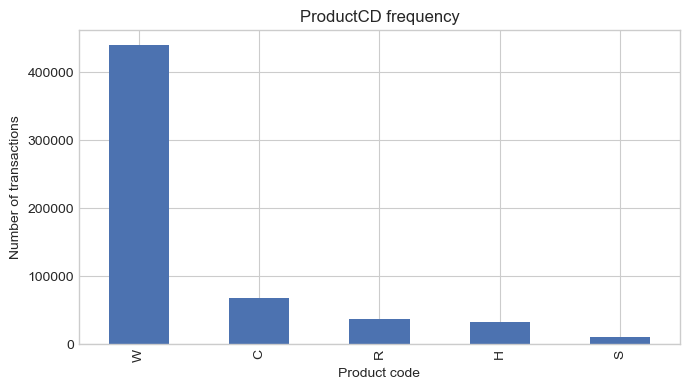

In [26]:
fig, ax = plt.subplots(figsize=(7, 4))
prod_freq["count"].plot.bar(ax=ax, color="#4C72B0")
ax.set_title("ProductCD frequency")
ax.set_xlabel("Product code")
ax.set_ylabel("Number of transactions")
plt.tight_layout()
plt.show()

Product code `W` dominates the dataset, with the remaining four codes (`C`, `R`, `H`, `S`) sharing the minority — an uneven mix that illustrates how institutional transaction portfolios differ in practice, the heterogeneity Section 7 models.

### 4.4 Card columns (card1–card6)

In [27]:
for c in ["card4", "card6"]:
    print(f"--- {c} ---")
    print(txn[c].value_counts(dropna=False).to_string(), "\n")

--- card4 ---


card4
visa                384767
mastercard          189217
american express      8328
discover              6651
NaN                   1577 

--- card6 ---
card6
debit              439938
credit             148986
NaN                  1571
debit or credit        30
charge card            15 



In [28]:
txn[["card1", "card2", "card3", "card5"]].describe()

,card1,card2,card3,card5
count,590540.000000,581607.000000,588975.000000,586281.000000
mean,9898.734658,362.555488,153.194925,199.278897
std,4901.170153,157.793246,11.336444,41.244453
min,1000.000000,100.000000,100.000000,100.000000
25%,6019.000000,214.000000,150.000000,166.000000
50%,9678.000000,361.000000,150.000000,226.000000
75%,14184.000000,512.000000,150.000000,226.000000
max,18396.000000,600.000000,231.000000,237.000000


Visa and Mastercard dominate `card4` (card network); debit and credit dominate `card6` (card type). `card1–card3` and `card5` are anonymised numeric identifiers whose magnitudes carry no direct meaning.

### 4.5 C1–C14 (anonymised counts)

In [29]:
c_cols = [f"C{i}" for i in range(1, 15)]
txn[c_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
C1,590540.0,14.092458,133.569018,0.0,1.0,1.0,3.0,4685.0
C2,590540.0,15.269734,154.668899,0.0,1.0,1.0,3.0,5691.0
C3,590540.0,0.005644,0.150536,0.0,0.0,0.0,0.0,26.0
C4,590540.0,4.092185,68.848459,0.0,0.0,0.0,0.0,2253.0
C5,590540.0,5.571526,25.786976,0.0,0.0,0.0,1.0,349.0
C6,590540.0,9.071082,71.508467,0.0,1.0,1.0,2.0,2253.0
C7,590540.0,2.848478,61.727304,0.0,0.0,0.0,0.0,2255.0
C8,590540.0,5.144574,95.378574,0.0,0.0,0.0,0.0,3331.0
C9,590540.0,4.480240,16.674897,0.0,0.0,1.0,2.0,210.0
C10,590540.0,5.240343,95.581443,0.0,0.0,0.0,0.0,3257.0


All C-features are non-negative counts with medians near zero or one and extreme maxima in the thousands — heavy right tails typical of per-entity counting features.

### 4.6 D1–D15 (time deltas)

In [30]:
d_cols = [f"D{i}" for i in range(1, 16)]
txn[d_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
D1,589271.0,94.347568,157.660387,0.0,0.000000,3.000000,122.000000,640.000000
D2,309743.0,169.563231,177.315865,0.0,26.000000,97.000000,276.000000,640.000000
D3,327662.0,28.343348,62.384721,0.0,1.000000,8.000000,27.000000,819.000000
D4,421618.0,140.002441,191.096774,-122.0,0.000000,26.000000,253.000000,869.000000
D5,280699.0,42.335965,89.000144,0.0,1.000000,10.000000,32.000000,819.000000
D6,73187.0,69.805717,143.669253,-83.0,0.000000,0.000000,40.000000,873.000000
D7,38917.0,41.638950,99.743264,0.0,0.000000,0.000000,17.000000,843.000000
D8,74926.0,146.058108,231.663840,0.0,0.958333,37.875000,187.958328,1707.791626
D9,74926.0,0.561057,0.316880,0.0,0.208333,0.666666,0.833333,0.958333
D10,514518.0,123.982137,182.615225,0.0,0.000000,15.000000,197.000000,876.000000


The D-features (time deltas in days) show substantial missingness and, as expected, heavy right skew: most deltas are small, but maxima reach hundreds of days.

**Key Findings — Section 4**
- `TransactionAmt` is strongly right-skewed (moment skewness ≈ 14, while the median-based Pearson coefficient ≈ 0.83 understates the heavy tail; log-normal-like shape), implying a log transform will be appropriate at preprocessing time.
- The data span ~6 months with weekly periodicity and at least one seasonal volume spike; `TransactionDT` is an offset, not a calendar timestamp.
- Categorical structure is uneven: `ProductCD` is dominated by one code and `card4`/`card6` by two values each, while C- and D-features are heavy-tailed counts/deltas with notable missingness.

## 5. Fraud-Stratified Analysis

How does the fraud rate vary across key features? This matters directly for model validation and for the plausibility of non-IID client splits.

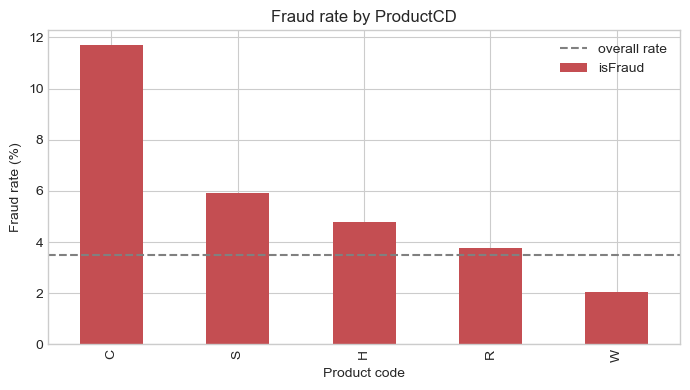

In [31]:
fraud_by_prod = txn.groupby("ProductCD")["isFraud"].mean().sort_values(ascending=False) * 100
fig, ax = plt.subplots(figsize=(7, 4))
fraud_by_prod.plot.bar(ax=ax, color="#C44E52")
ax.axhline(txn["isFraud"].mean() * 100, color="gray", ls="--", label="overall rate")
ax.set_title("Fraud rate by ProductCD")
ax.set_xlabel("Product code")
ax.set_ylabel("Fraud rate (%)")
ax.legend()
plt.tight_layout()
plt.show()

Fraud rates differ markedly across product codes (code `C` is several times the overall rate), so `ProductCD` is predictive, and the spread in its fraud rates shows how sharply fraud prevalence can differ across transaction mixes — realistic grounds for the label-skew partitioning characterised in Section 7.

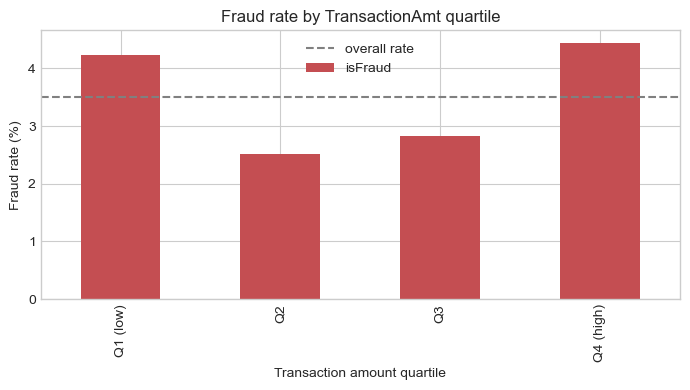

In [32]:
amt_quartile = pd.qcut(txn["TransactionAmt"], 4, labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"])
fraud_by_q = txn.groupby(amt_quartile, observed=True)["isFraud"].mean() * 100
fig, ax = plt.subplots(figsize=(7, 4))
fraud_by_q.plot.bar(ax=ax, color="#C44E52")
ax.axhline(txn["isFraud"].mean() * 100, color="gray", ls="--", label="overall rate")
ax.set_title("Fraud rate by TransactionAmt quartile")
ax.set_xlabel("Transaction amount quartile")
ax.set_ylabel("Fraud rate (%)")
ax.legend()
plt.tight_layout()
plt.show()

Fraud rate varies by amount quartile rather than rising monotonically with value — amount alone is informative but far from sufficient.

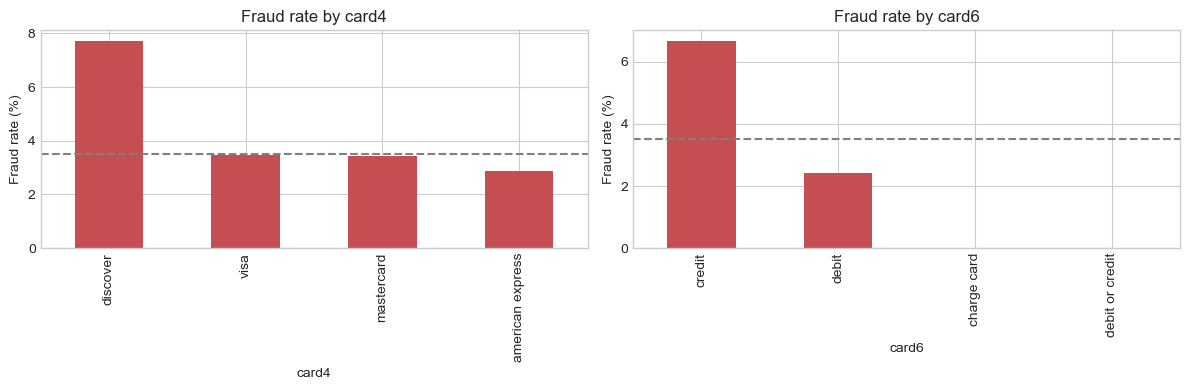

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["card4", "card6"]):
    rates = txn.groupby(col)["isFraud"].mean().sort_values(ascending=False) * 100
    rates.plot.bar(ax=ax, color="#C44E52")
    ax.axhline(txn["isFraud"].mean() * 100, color="gray", ls="--")
    ax.set_title(f"Fraud rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Fraud rate (%)")
plt.tight_layout()
plt.show()

Card network and card type both stratify the fraud rate (credit cards show elevated rates relative to debit), confirming the card features as useful inputs.

In [34]:
mean_amt = txn.groupby("isFraud")["TransactionAmt"].mean()
print(f"Mean TransactionAmt - legitimate: {mean_amt[0]:,.2f} USD | fraud: {mean_amt[1]:,.2f} USD")

Mean TransactionAmt - legitimate: 134.51 USD | fraud: 149.24 USD


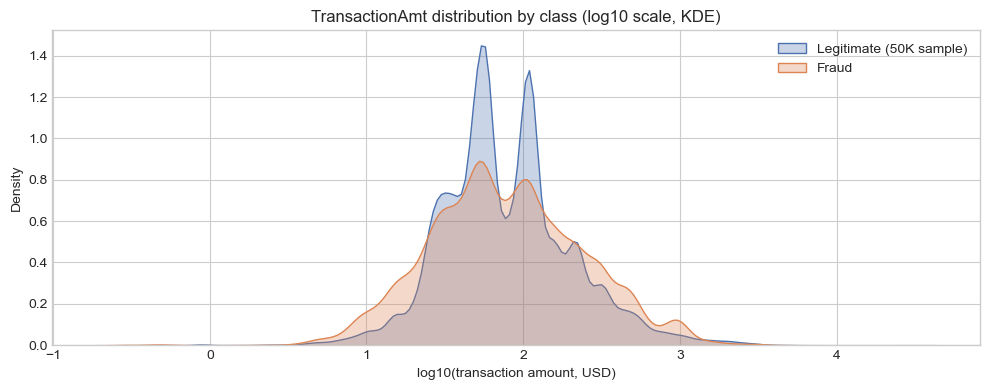

In [35]:
rng = np.random.default_rng(RANDOM_STATE)
legit_amt = txn.loc[txn["isFraud"] == 0, "TransactionAmt"]
legit_sample = legit_amt.sample(50_000, random_state=RANDOM_STATE)  # subsample for KDE speed
fraud_amt = txn.loc[txn["isFraud"] == 1, "TransactionAmt"]

fig, ax = plt.subplots(figsize=(10, 4))
sns.kdeplot(np.log10(legit_sample[legit_sample > 0]), ax=ax, label="Legitimate (50K sample)", fill=True, alpha=0.3)
sns.kdeplot(np.log10(fraud_amt[fraud_amt > 0]), ax=ax, label="Fraud", fill=True, alpha=0.3)
ax.set_title("TransactionAmt distribution by class (log10 scale, KDE)")
ax.set_xlabel("log10(transaction amount, USD)")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.show()

The fraud and legitimate amount distributions overlap heavily on the log scale, with fraud showing a modest shift toward higher values — no single feature separates the classes.

**Discriminativeness comment:** individually, `ProductCD`, `card4`/`card6`, and `TransactionAmt` each shift the fraud rate away from the ~3.5% baseline, but the KDE overlap shows that univariate signals are weak. A multivariate learner (the planned MLP) is required; these stratified views will later serve as sanity checks that the trained model attends to plausible signals.

**Key Findings — Section 5**
- Fraud rate varies several-fold across `ProductCD` and meaningfully across card network/type — features are discriminative in aggregate.
- Mean fraud amounts exceed mean legitimate amounts, but class-conditional amount distributions overlap heavily (log-scale KDE).
- No univariate feature cleanly separates classes, motivating the multivariate MLP and providing baseline sanity checks for model validation.

## 6. Outlier Analysis

In [36]:
mu, sigma = amt.mean(), amt.std()
threshold = mu + 3 * sigma
outliers = txn[amt > threshold]
print(f"Mean: {mu:,.2f} USD | SD: {sigma:,.2f} USD | +3 SD threshold: {threshold:,.2f} USD")
print(f"Transactions above +3 SD: {len(outliers):,} ({len(outliers) / len(txn):.3%})")
print(f"Fraud rate among these outliers: {outliers['isFraud'].mean():.2%} "
      f"(overall: {txn['isFraud'].mean():.2%})")

Mean: 135.03 USD | SD: 239.16 USD | +3 SD threshold: 852.51 USD
Transactions above +3 SD: 10,093 (1.709%)
Fraud rate among these outliers: 5.33% (overall: 3.50%)


A small fraction of transactions exceed +3 SD in amount. **These are flagged, not removed:** in fraud detection, extreme transaction values can themselves be genuine fraud signals rather than measurement noise. Removing them would discard exactly the cases the model must learn to handle. They are retained and noted as a robustness consideration for training, and the heavy tail they produce reinforces the case for a log transform of amounts at the preprocessing stage.

## 7. FL Partitioning Analysis (non-IID characterisation)

The AQ-FL experiment simulates **10 financial-institution clients** partitioned with a **Dirichlet label-skew scheme** (Hsu et al., 2019, arXiv:1909.06335): for each class, client proportions are drawn from $\mathrm{Dir}(\alpha)$ and that class's rows are allocated accordingly. The concentration parameter $\alpha$ tunes heterogeneity — large $\alpha$ approaches an IID split, small $\alpha$ concentrates each class on a few clients — so a single mechanism produces both quantity skew and label-distribution skew, and it is the standard partitioning protocol in the FL literature.

In [37]:
rng = np.random.default_rng(RANDOM_STATE)
N_CLIENTS = 10

def dirichlet_partition(labels, n_clients, alpha, rng):
    assignment = np.empty(len(labels), dtype=int)
    for c in np.unique(labels):
        idx = np.where(labels == c)[0]
        rng.shuffle(idx)
        props = rng.dirichlet(np.full(n_clients, alpha))
        cuts = (np.cumsum(props[:-1]) * len(idx)).astype(int)
        for k, part in enumerate(np.split(idx, cuts)):
            assignment[part] = k
    return assignment

def client_stats(labels, assignment):
    stats = (pd.DataFrame({"client": assignment, "label": labels})
             .groupby("client")["label"]
             .agg(rows="size", fraud_count="sum", fraud_rate="mean"))
    stats["fraud_rate_pct"] = (stats["fraud_rate"] * 100).round(3)
    return stats

In [38]:
labels = txn["isFraud"].to_numpy()
alphas = [100.0, 1.0, 0.5, 0.1]
partitions = {a: client_stats(labels, dirichlet_partition(labels, N_CLIENTS, a, rng))
              for a in alphas}

summary = pd.DataFrame({
    "min rows/client": [partitions[a]["rows"].min() for a in alphas],
    "max rows/client": [partitions[a]["rows"].max() for a in alphas],
    "min fraud/client": [partitions[a]["fraud_count"].min() for a in alphas],
    "fraud-rate std": [round(partitions[a]["fraud_rate"].std(), 5) for a in alphas],
}, index=pd.Index(alphas, name="alpha"))
summary

,min rows/client,max rows/client,min fraud/client,fraud-rate std
alpha,,,,
100.0,44670,75123,1896,0.00610
1.0,10336,122958,856,0.02742
0.5,954,339715,16,0.30549
0.1,306,235056,0,0.43454


In [39]:
# Calibration anchor: what does NATURAL institutional heterogeneity look like?
# Split by ProductCD (institutions specialising in different transaction types),
# two clients per code -> 10 clients, and measure the spread.
prod_rates = []
for prod, grp in txn.groupby("ProductCD"):
    for k, part in enumerate(np.array_split(grp, 2)):
        prod_rates.append({"client": f"{prod}_{k}", "rows": len(part),
                           "fraud_rate": part["isFraud"].mean()})
prod_df = pd.DataFrame(prod_rates)
natural_std = prod_df["fraud_rate"].std()

print(prod_df.to_string(index=False))
print(f"\nNatural (ProductCD) per-client fraud-rate std: {natural_std:.4f}")
for a in alphas:
    print(f"  Dirichlet alpha={a:<6} std: {partitions[a]['fraud_rate'].std():.4f}")
print(f"\n-> alpha = 1.0 is the closest match to the natural split; "
      f"adopted as the primary non-IID condition.")

D:\Anaconda\Lib\site-packages\numpy\_core\fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


client   rows  fraud_rate
   C_0  34260    0.106859
   C_1  34259    0.126886
   H_0  16512    0.018956
   H_1  16512    0.076369
   R_0  18850    0.008806
   R_1  18849    0.066847
   S_0   5814    0.056244
   S_1   5814    0.061748
   W_0 219835    0.020347
   W_1 219835    0.020452

Natural (ProductCD) per-client fraud-rate std: 0.0399
  Dirichlet alpha=100.0  std: 0.0061
  Dirichlet alpha=1.0    std: 0.0274
  Dirichlet alpha=0.5    std: 0.3055
  Dirichlet alpha=0.1    std: 0.4345

-> alpha = 1.0 is the closest match to the natural split; adopted as the primary non-IID condition.


Per-client detail under the primary non-IID condition, $\alpha = 1.0$:

In [40]:
partitions[1.0]

,rows,fraud_count,fraud_rate,fraud_rate_pct
client,,,,
0,122958,6784,0.055173,5.517
1,58533,1064,0.018178,1.818
2,10336,856,0.082817,8.282
3,101623,2237,0.022013,2.201
4,24507,1015,0.041417,4.142
5,65085,1399,0.021495,2.149
6,50336,2727,0.054176,5.418
7,49794,1039,0.020866,2.087
8,82077,1281,0.015607,1.561


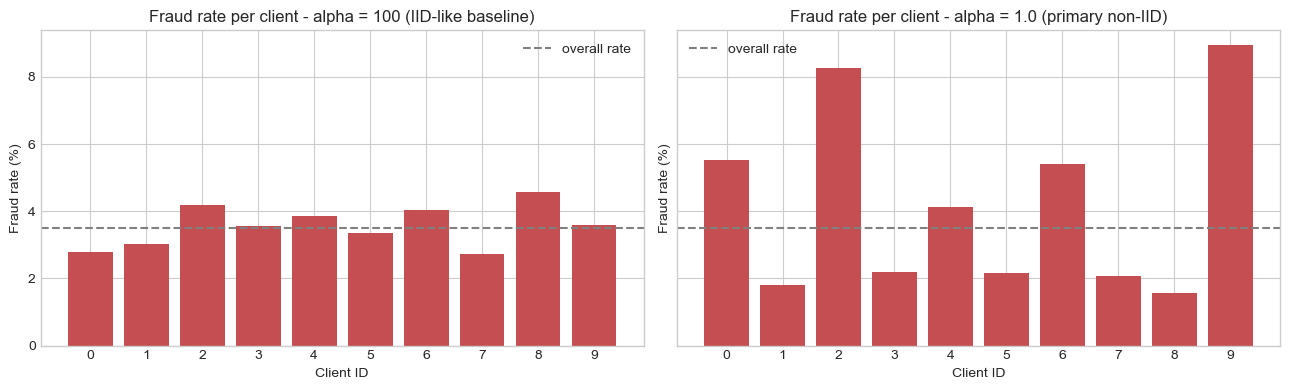

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, a, name in [(axes[0], 100.0, "alpha = 100 (IID-like baseline)"),
                    (axes[1], 1.0, "alpha = 1.0 (primary non-IID)")]:
    stats = partitions[a]
    ax.bar(stats.index.astype(str), stats["fraud_rate"] * 100, color="#C44E52")
    ax.axhline(txn["isFraud"].mean() * 100, color="gray", ls="--", label="overall rate")
    ax.set_title(f"Fraud rate per client - {name}")
    ax.set_xlabel("Client ID")
    ax.set_ylabel("Fraud rate (%)")
    ax.legend()
plt.tight_layout()
plt.show()

At $\alpha = 100$ every client approximates the global ~3.5% fraud rate with near-equal sizes — the same mechanism reproducing an IID split. As $\alpha$ falls, client sizes and fraud rates diverge sharply: at $\alpha = 0.5$ one client ends up 98.8% fraudulent, and at $\alpha = 0.1$ some clients receive no fraud cases at all.

**Partitioning decision:** the FL experiments use the Dirichlet scheme throughout — $\alpha = 100$ as the IID-like baseline, $\alpha = 1.0$ as the primary non-IID condition, and $\alpha = 0.5$ as a stress case. The primary $\alpha$ is calibrated against measured natural heterogeneity rather than chosen by convention: splitting the data by `ProductCD` (institutions specialising in different transaction types) gives a per-client fraud-rate std of 0.0399, which $\alpha = 1.0$ reproduces most closely at 0.0274. $\alpha = 0.5$ (std 0.305) is an order of magnitude more extreme and concentrates roughly 70% of all fraud on a single client — a configuration a Krum-style filter would reject every round, so it is retained only to probe breaking behaviour. $\alpha = 0.1$ is excluded from the experimental conditions because several clients receive zero fraud cases; it remains in the sweep table for completeness. The gap between baseline and primary quantifies the heterogeneity cost AQ-FL's aggregation is designed to absorb.

*Working note: $\alpha = 0.5$ was the primary condition in the first draft of this section. The 98.8%-fraud client only became visible after printing the per-client table, which is what prompted measuring the ProductCD split as a calibration target.*

**Key Findings — Section 7**
- A Dirichlet label-skew partition provides one tunable mechanism for all conditions: $\alpha = 100$ for IID-like homogeneity, $\alpha = 1.0$ for realistic heterogeneity, $\alpha = 0.5$ for stress.
- The primary $\alpha$ is calibrated to the measured natural split (0.0399), not chosen arbitrarily — $\alpha = 1.0$ gives 0.0274.
- At small $\alpha$ the minimum per-client fraud count collapses to zero, so extreme settings test label sparsity rather than realistic heterogeneity.

## 8. Data Card — IEEE-CIS Fraud Detection

*Format follows Gebru et al. (2021), "Datasheets for Datasets."*

**Motivation.** Created by Vesta Corporation and released through the Kaggle *IEEE-CIS Fraud Detection* competition (2019, with the IEEE Computational Intelligence Society) to benchmark machine-learning approaches to card-not-present transaction fraud.

**Composition.** 590,540 labelled transactions (`train_transaction.csv`, 394 columns) and 144,233 identity records (`train_identity.csv`, 41 columns), joined via `TransactionID` (left join; ~24% coverage). Binary label `isFraud` (~3.5% positive). Features span transaction attributes (amount, time offset, product code, card, address, distance), anonymised counts (`C1–C14`), time deltas (`D1–D15`), match flags (`M1–M9`), Vesta-engineered features (`V1–V339`), and device/identity attributes (`id_01–id_38`, `DeviceType`, `DeviceInfo`).

**Collection & Curation.** Real e-commerce transactions from Vesta's production systems. Vesta anonymised feature names and value semantics; the timestamp is an offset from an undisclosed reference.

**Preprocessing applied (this notebook).** Left join of the two tables and a structural audit (duplicates, null rates, dtype checks) only. **No imputation, feature engineering, encoding, or scaling has been performed.**

**Known limitations.** The meaning of `V1–V339` is unknown; identity coverage is only ~24% of transactions (≈76% of rows lack identity fields); demographic information is absent due to anonymisation, precluding direct fairness auditing; labels reflect Vesta's internal fraud determination process.

**Intended use.** Training and benchmarking fraud-detection models; in this project, as the **primary benchmark** for federated learning experiments across 10 simulated institutions.

**Distribution & Maintenance.** Distributed via Kaggle under the competition's terms; the dataset is static with no updates planned.

**Distribution & usage rights.** Publicly distributed through Kaggle as part of the IEEE-CIS Fraud Detection competition (2019); used here for non-commercial academic research consistent with the competition rules.